<a href="https://colab.research.google.com/github/vighneshkhot10/CSL701-ce24_Machine-Learning-Lab/blob/main/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name :Vighnesh D. Khot

Batch :CE02


Roll Number :CE19




### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extendedThe Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

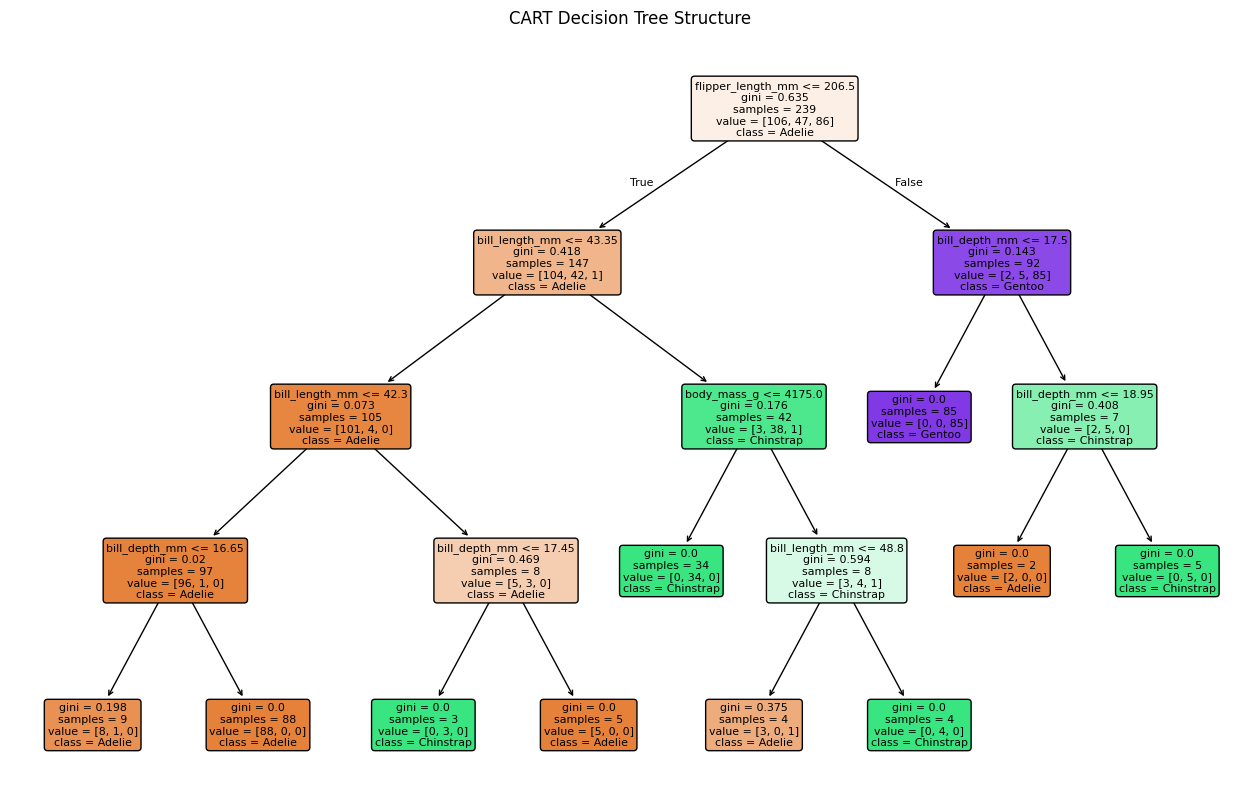

DecisionTreeClassifier(max_depth=4, random_state=42)

In [ ]:
# Plot the decision tree structure
plt.figure(figsize=(16, 10))
plot_tree(cart_model, feature_names=features, class_names=le.classes_, filled=True, rounded=True)
plt.title("CART Decision Tree Structure")
plt.show()

# Train a model on 2D space (bill_length_mm, flipper_length_mm) for visualization
features_2d = ['bill_length_mm', 'flipper_length_mm']
X_train_2d = X_train[features_2d]
X_test_2d = X_test[features_2d]

cart_model_2d = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
cart_model_2d.fit(X_train_2d, y_train)

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

# Download Palmer Penguins Dataset Extended from GitHub/Kaggle Mirror
url = 'https://raw.githubusercontent.com/mcnakhaee/palmerpenguins/master/palmerpenguins/data/penguins.csv'
df = pd.read_csv(url)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [ ]:
# Drop rows with missing values in key features
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
df_clean = df.dropna(subset=features + ['species']).copy()

# Define features and target
X = df_clean[features]
y = df_clean['species']

# Encode categorical target species
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Preprocessed features shape:", X.shape)
print("Target distribution:", dict(zip(*np.unique(y, return_counts=True))))

Preprocessed features shape: (342, 4)
Target distribution: {'Adelie': np.int64(151), 'Chinstrap': np.int64(68), 'Gentoo': np.int64(123)}


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded)
print(f"Training instances: {X_train.shape[0]}, Testing instances: {X_test.shape[0]}")

Training instances: 239, Testing instances: 103


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [ ]:
# Instantiate and fit CART classifier using Gini criterion
cart_model = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
cart_model.fit(X_train, y_train)

# Predict on the test set
y_pred_cart = cart_model.predict(X_test)

# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

In [ ]:
# Accuracy
accuracy_cart = accuracy_score(y_test, y_pred_cart)
print(f"CART Classifier Accuracy: {accuracy_cart * 100:.2f}%\n")

# Confusion Matrix
print("Confusion Matrix:")
cm_cart = confusion_matrix(y_test, y_pred_cart)
display(pd.DataFrame(cm_cart, index=le.classes_, columns=le.classes_))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_cart, target_names=le.classes_))

CART Classifier Accuracy: 99.03%

Confusion Matrix:


,Adelie,Chinstrap,Gentoo
Adelie,44,1,0
Chinstrap,0,21,0
Gentoo,0,0,37



Classification Report:
              precision    recall  f1-score   support

      Adelie       1.00      0.98      0.99        45
   Chinstrap       0.95      1.00      0.98        21
      Gentoo       1.00      1.00      1.00        37

    accuracy                           0.99       103
   macro avg       0.98      0.99      0.99       103
weighted avg       0.99      0.99      0.99       103



# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


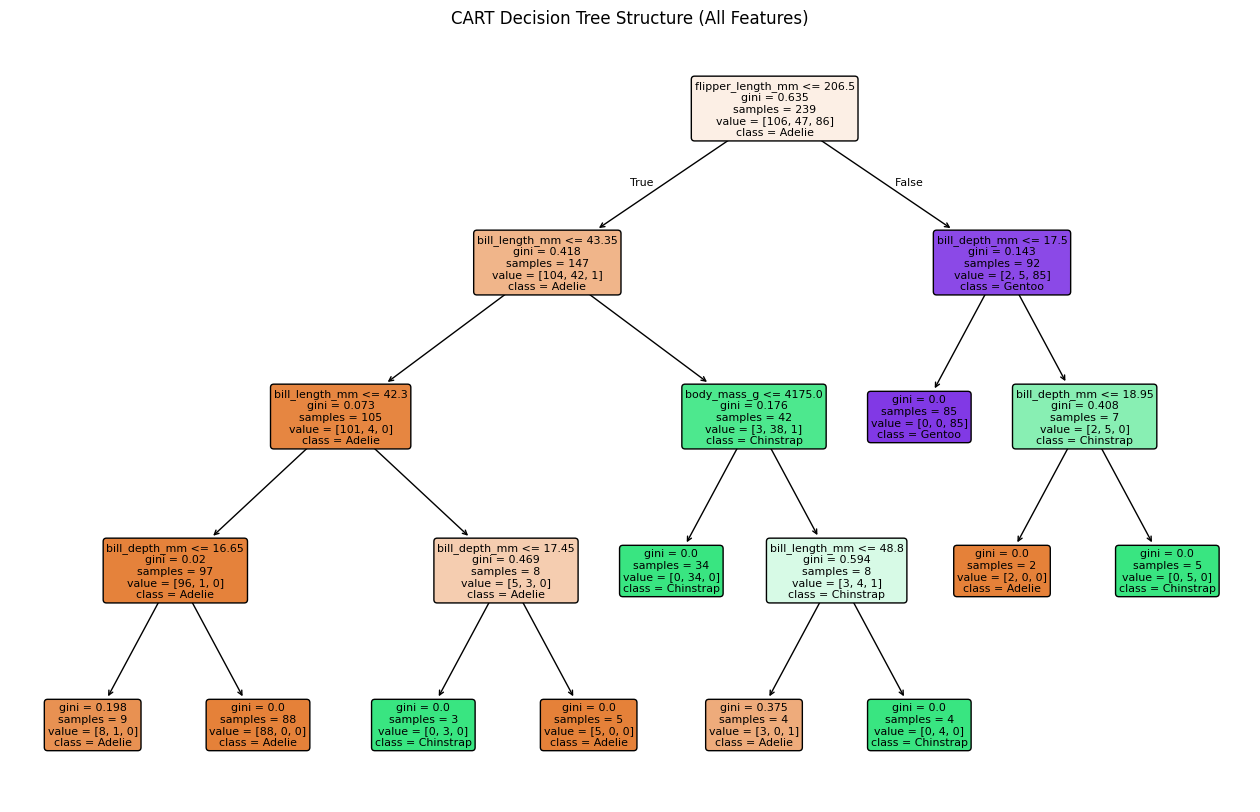

DecisionTreeClassifier(max_depth=4, random_state=42)

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Visualize Tree Structure
plt.figure(figsize=(16, 10))
plot_tree(cart_model, feature_names=features, class_names=le.classes_, filled=True, rounded=True)
plt.title("CART Decision Tree Structure (All Features)")
plt.show()

# 2. Select 2-D Features and Train 2-D Model
features_2d = ['bill_length_mm', 'flipper_length_mm']
X_train_2d = X_train[features_2d]
X_test_2d = X_test[features_2d]

cart_model_2d = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
cart_model_2d.fit(X_train_2d, y_train)

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

In [ ]:
# Train a Logistic Regression model as linear baseline in 2D
logreg_model_2d = LogisticRegression(max_iter=1000, random_state=42)
logreg_model_2d.fit(X_train_2d, y_train)

LogisticRegression(max_iter=1000, random_state=42)

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


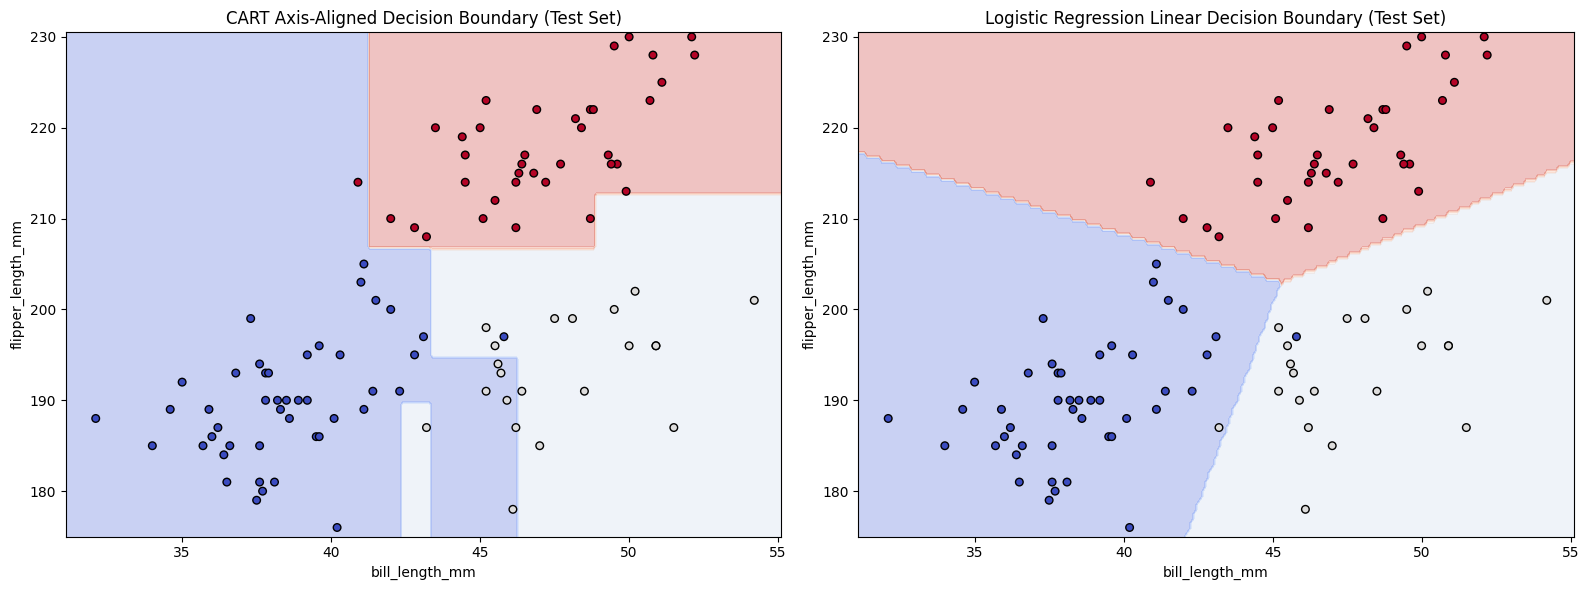

In [ ]:
# Function to plot decision boundaries
def plot_boundaries(ax, model, X_data, y_data, title):
    x_min, x_max = X_data.iloc[:, 0].min() - 1, X_data.iloc[:, 0].max() + 1
    y_min, y_max = X_data.iloc[:, 1].min() - 1, X_data.iloc[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.5))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    scatter = ax.scatter(X_data.iloc[:, 0], X_data.iloc[:, 1], c=y_data, edgecolors='k', cmap=plt.cm.coolwarm, s=30)
    ax.set_xlabel(X_data.columns[0])
    ax.set_ylabel(X_data.columns[1])
    ax.set_title(title)
    return scatter

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot CART Boundary
plot_boundaries(ax1, cart_model_2d, X_test_2d, y_test, "CART Axis-Aligned Decision Boundary (Test Set)")

# Plot Logistic Regression Boundary
plot_boundaries(ax2, logreg_model_2d, X_test_2d, y_test, "Logistic Regression Linear Decision Boundary (Test Set)")

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


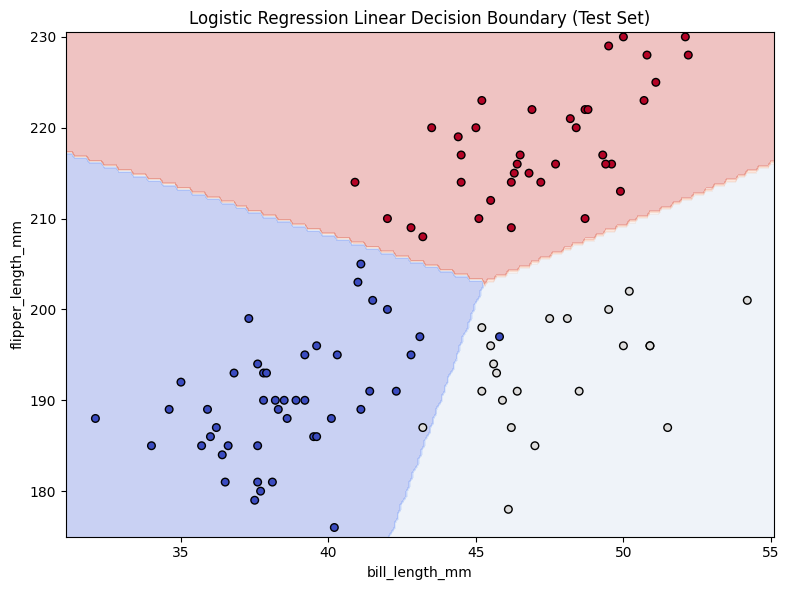

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Configure figure size
plt.figure(figsize=(8, 6))

# Plot the decision boundaries for the Logistic Regression model
plot_boundaries(plt.gca(), logreg_model_2d, X_test_2d, y_test, "Logistic Regression Linear Decision Boundary (Test Set)")
plt.tight_layout()
plt.show()

In [ ]:
# Calculate and display the confusion matrix for the 2D Logistic Regression model
y_pred_logreg_2d = logreg_model_2d.predict(X_test_2d)
cm_logreg = confusion_matrix(y_test, y_pred_logreg_2d)

print("Logistic Regression (2D) Confusion Matrix:")
cm_df = pd.DataFrame(cm_logreg, index=le.classes_, columns=le.classes_)
display(cm_df)

Logistic Regression (2D) Confusion Matrix:


,Adelie,Chinstrap,Gentoo
Adelie,44,1,0
Chinstrap,1,20,0
Gentoo,0,0,37


# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

# Evaluate and compare metrics (Accuracy, Confusion Matrix, Classification Report)
y_pred_cart_2d = cart_model_2d.predict(X_test_2d)
y_pred_logreg_2d = logreg_model_2d.predict(X_test_2d)

print("=== CART Classifier (2D) Performance ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_cart_2d) * 100:.2f}%")
print("\nConfusion Matrix:")
print(pd.DataFrame(confusion_matrix(y_test, y_pred_cart_2d), index=le.classes_, columns=le.classes_))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_cart_2d, target_names=le.classes_))

print("\n=== Logistic Regression (2D) Performance ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_logreg_2d) * 100:.2f}%")
print("\nConfusion Matrix:")
print(pd.DataFrame(confusion_matrix(y_test, y_pred_logreg_2d), index=le.classes_, columns=le.classes_))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_logreg_2d, target_names=le.classes_))